# Meme Kanseri Tahmini
Breast Cancer Wisconsin veri seti. Etiketler: `0` = kötü huylu (kanser), `1` = iyi huylu.
Tüm metrikler gerçek model çıktılarından hesaplanır; tahminlere hiçbir müdahale yoktur.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, confusion_matrix)

In [2]:
veri = load_breast_cancer()
df = pd.DataFrame(veri.data, columns=veri.feature_names)
df['hedef'] = veri.target
print(f'Veri seti boyutu: {df.shape}')
print(f'Kötü huylu (0): {(df.hedef==0).sum()}, İyi huylu (1): {(df.hedef==1).sum()}')
print('Eksik değer:', df.isnull().sum().sum())
df.head()

Veri seti boyutu: (569, 31)
Kötü huylu (0): 212, İyi huylu (1): 357
Eksik değer: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,hedef
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


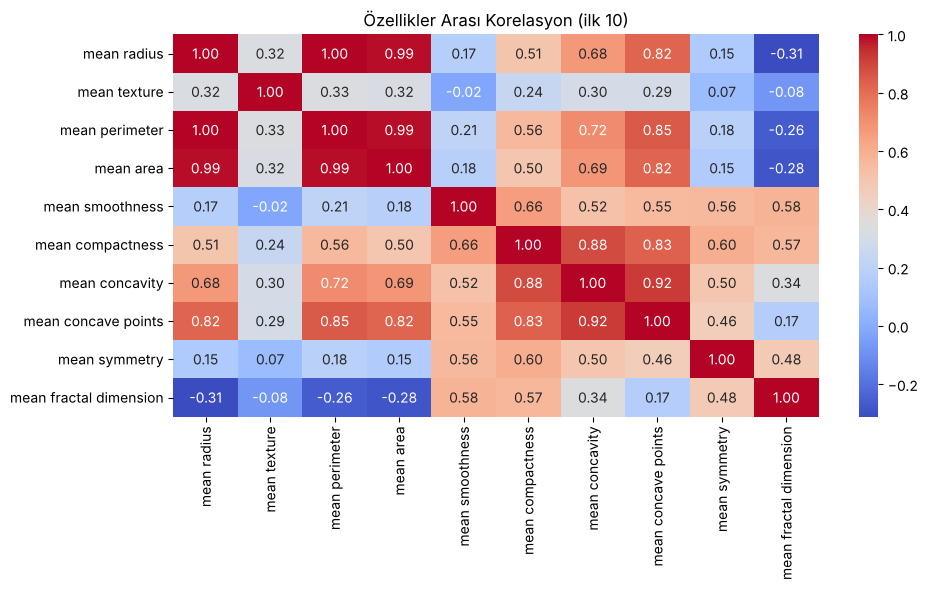

In [3]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.iloc[:, :10].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Özellikler Arası Korelasyon (ilk 10)')
plt.tight_layout(); plt.show()

## Veri hazırlama
Ölçekleme `Pipeline` içinde yapılır; böylece cross-validation'da veri sızıntısı (data leakage) olmaz.

In [4]:
X = df.drop('hedef', axis=1)
y = df['hedef']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(len(X_train), 'eğitim /', len(X_test), 'test')

455 eğitim / 114 test


## Modeller (hiçbir tahmine müdahale yok)

In [5]:
modeller = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
}
cv = StratifiedKFold(5, shuffle=True, random_state=42)
egitilmis, satirlar = {}, []
for ad, m in modeller.items():
    pipe = make_pipeline(StandardScaler(), m).fit(X_train, y_train)
    p = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    egitilmis[ad] = pipe
    satirlar.append({
        'Model': ad,
        'Accuracy': accuracy_score(y_test, p),
        'Kanser Recall': recall_score(y_test, p, pos_label=0),
        'Kanser Precision': precision_score(y_test, p, pos_label=0),
        'F1 (kanser)': f1_score(y_test, p, pos_label=0),
        'AUC-ROC': roc_auc_score(y_test, proba),
        '5-Fold CV Acc': cross_val_score(make_pipeline(StandardScaler(), m), X, y, cv=cv).mean(),
    })
sonuc = pd.DataFrame(satirlar)
print(sonuc.round(4).to_string(index=False))

              Model  Accuracy  Kanser Recall  Kanser Precision  F1 (kanser)  AUC-ROC  5-Fold CV Acc
Logistic Regression    0.9825         0.9762            0.9762       0.9762   0.9954         0.9737
      Decision Tree    0.9123         0.9286            0.8478       0.8864   0.9157         0.9104
      Random Forest    0.9561         0.9286            0.9512       0.9398   0.9939         0.9561
          KNN (k=5)    0.9561         0.9286            0.9512       0.9398   0.9788         0.9631


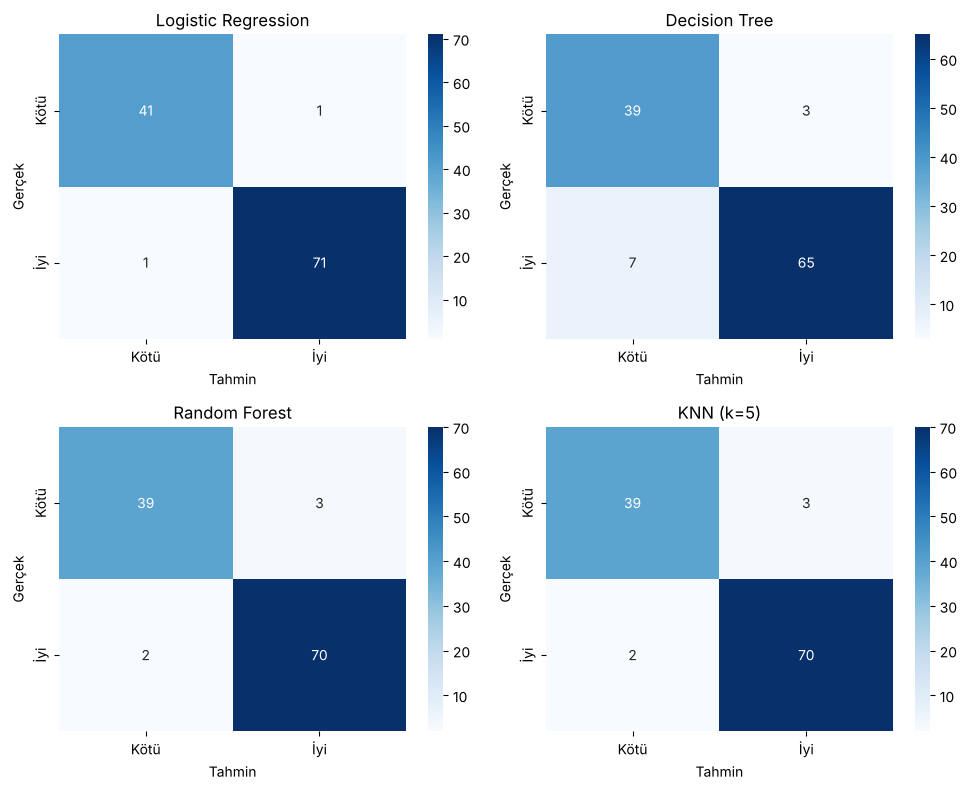

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (ad, pipe) in zip(axes.flatten(), egitilmis.items()):
    cm = confusion_matrix(y_test, pipe.predict(X_test))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Kötü', 'İyi'], yticklabels=['Kötü', 'İyi'])
    ax.set_title(ad); ax.set_xlabel('Tahmin'); ax.set_ylabel('Gerçek')
plt.tight_layout(); plt.show()

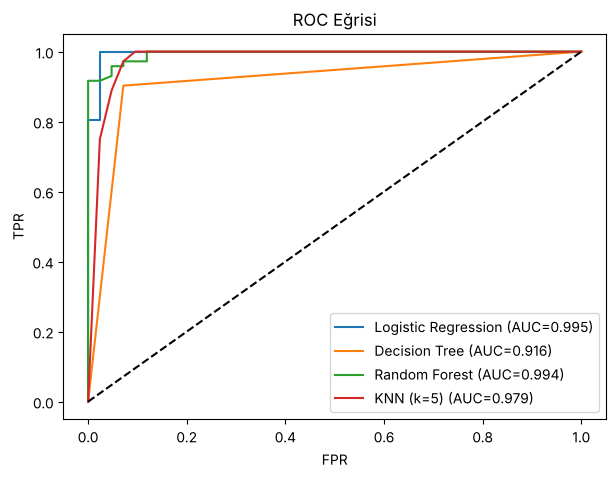

In [7]:
plt.figure(figsize=(7, 5))
for ad, pipe in egitilmis.items():
    fpr, tpr, _ = roc_curve(y_test, pipe.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=f"{ad} (AUC={roc_auc_score(y_test, pipe.predict_proba(X_test)[:,1]):.3f})")
plt.plot([0, 1], [0, 1], 'k--'); plt.legend(); plt.xlabel('FPR'); plt.ylabel('TPR')
plt.title('ROC Eğrisi'); plt.show()